# Water Quality Assessment using Implicative Fuzzy Inference Systems
**Project Overview:** This notebook implements a fuzzy logic-based approach to evaluate river water quality based on physical and chemical parameters. It utilizes an **Implicative Inference System** to map environmental data (such as oxygen levels, nitrogen, and phosphorus) to quality categories ranging from "Very Good" to "Very Bad".

### Key Features:
* **Data Processing:** Loads and filters river quality datasets (`River_quality_data_2023.csv`) and predefined quality intervals (`Phisical_Chemical_quality_intervals.csv`).
* **Fuzzy Inference:** Implements an `ImplicativeInferenceSystem` using Łukasiewicz t-norms and alternative modifiers.
* **Defuzzification Analysis:** Compares different defuzzification methods, specifically **Center of Gravity (CoG)** and **Mean of Maxima (MoM)**.
* **Decision Support:** Includes a "Payoff" analysis to evaluate the economic or environmental benefits of taking action (e.g., water cleaning) versus no action under varying levels of uncertainty.
* **Visualization:** Provides detailed plotting functions for membership functions, payoff heatmaps, and defuzzification comparisons.



In [50]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import find_peaks

from fuzzy_inference.fuzzy_utils.alpha_cuts import create_1d_hat_function_scipy 
from fuzzy_inference.payoff_function.simple_payoff_functions import simple_payoff_function
from fuzzy_inference.rule_bases.Implicative_model import ImplicativeInferenceSystem

from fuzzy_inference.payoff_function.perform_inference_and_voi import perform_infernece_and_evaluation_with_data

In [51]:
# Read the data for water quality
df_water_data = pd.read_csv(
    '../Data/River_quality_data_2023.csv',
    delimiter=',', 
    decimal=',' 
)
 

In [52]:
# Reads the data for quality intervals
df_quaity_intervals = pd.read_csv(
    '../Data/Phisical_Chemical_quality_intervals.csv',
    delimiter=',',
    encoding='windows-1252',   
    decimal=',' 
)

In [53]:
def filter_qualityGrid_from_data(water_type=1, water_kind="R"):
    """ Function to filter the quality evaluation grid based on water type and kind.

    Args:
        water_type (int): The water type to filter by
        water_kind (str): The water kind to filter by

    Returns:
        np.array : quality evaluation grid for the given water type and kind
    """    
    filtered_intervals = df_quaity_intervals[
        (df_quaity_intervals["Tips"] == water_type)
        & (df_quaity_intervals["Veids"] == water_kind)
    ]

    quality_columns = ["Augsta", "Laba", "Vid?ja", "Slikta", "?oti slikta"]
    numeric_data = filtered_intervals[quality_columns].apply(
        lambda column: pd.to_numeric(
            column.astype(str).str.replace(",", ".", regex=False),
            errors="coerce",
        )
    )

    return np.sort(numeric_data.to_numpy(), axis=1)

In [54]:
from matplotlib.pyplot import grid


def plot_membership_function(membership_value, output_center_of_gravity, mean_of_maxima,
                             grid = np.array([0, 0.25, 0.5, 0.75, 1]), crips_center = None, title = ''):
    """Function for plotting the membership function with deffuzified values 
    and intervals for crisp quality assessments.

    Args:
        membership_value (np.ndarray): contains the values of the membership function.
        output_center_of_gravity (float): the center of gravity value.
        mean_of_maxima (float): the mean of maxima value.
        grid (np.array, optional): the grid for quality intervals. 
        crips_center (float): The crisp evaluation point
        title (strl): title for the plot
    """    
 
    interval_colors = [
        '#00BFFF',  # Very good
        '#90EE90',  # Good
        '#FFFF00',  # Medium
        '#FFA500',  # Bad
        '#FF0000',  # Very bad
    ]
    
    for i in range(len(grid) - 1):
    
        if i == 0:
            plt.hlines(y=-0.007, xmin=grid[i], xmax=(grid[i]+grid[i+1])/2, colors=interval_colors[i], linewidth=5) 
        else:
            plt.hlines(y=-0.007, xmin=(grid[i-1]+grid[i])/2, xmax=(grid[i]+grid[i+1])/2, colors=interval_colors[i], linewidth=5)
    
    plt.hlines(y=-0.007, xmin=(grid[-1]+grid[-2])/2, xmax=grid[-1], colors=interval_colors[-1], linewidth=5)

    plt.plot(np.linspace(0.005, 1, membership_value.shape[0]), membership_value, label='Membership Function',  linewidth=3)
    plt.xlabel('Water Quality', fontsize=16)
    plt.ylabel('Membership Degree', fontsize=16)
    # plt.title(f"Membership value for {title}",fontsize=18)
    plt.axvline(output_center_of_gravity, color='blue', linestyle='--', label=f'Center of Gravity: {output_center_of_gravity:.3f}')
    plt.axvline(mean_of_maxima, color='green', linestyle='--', label=f'Mean of Maxima: {mean_of_maxima:.3f}')
    # if crips_center is not None:
    #     plt.axvline(crips_center, color='green', linestyle='--', label=f'Crisp evaluation {crips_center:.3f}')
    plt.grid(True)
    plt.legend(loc='upper left', fontsize=12)
    plt.tick_params(axis='both', which='major', labelsize=14)
    plt.show()

In [68]:
first_r7


Code             G327
Station_type       R1
BSP5             1.89
N_NH4+          0.143
N_total           2.7
O_2              7.95
P_total         0.074
Name: 18, dtype: object

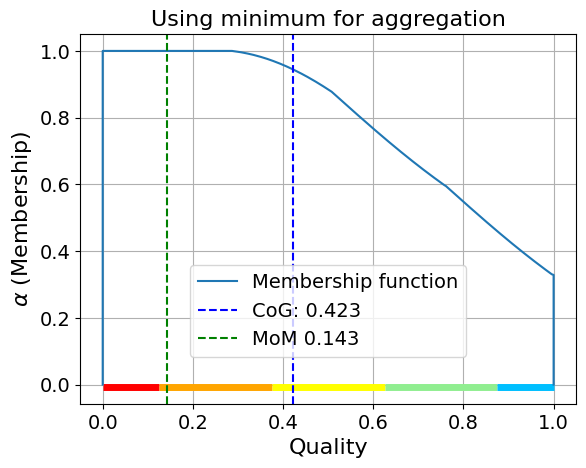

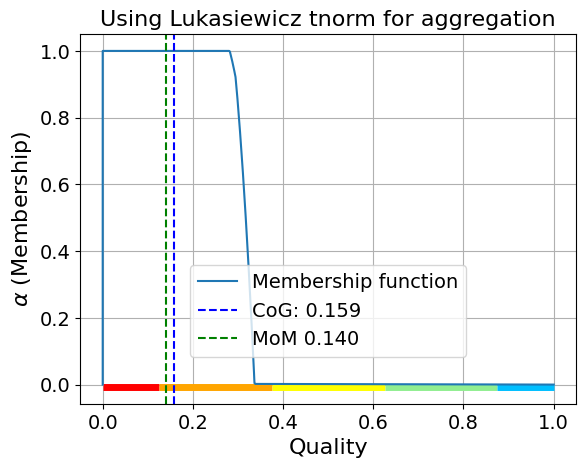

In [69]:
# Example of usage the Gosupe data.
first_r7 = df_water_data[df_water_data['Station_type'] == 'R1'].iloc[0]  
currenct_quality_grid = filter_qualityGrid_from_data(water_type=1)
Number_of_grid_points = 500
sample = first_r7.iloc[-5:].values.astype(float)
sample[3] = currenct_quality_grid[3,-1] - sample[3] + currenct_quality_grid[3,0] # The O_2 levels are being inverted, as they have reversed order.

mapping = lambda x: np.min(x)

implicative_system = ImplicativeInferenceSystem(currenct_quality_grid, type_of_modifier='altm',
                                                number_of_grid_points=Number_of_grid_points,
                                                type_of_tnorm='luk', aggregate_with_same_tnorm=False,
                                                mapping_to_consequent=mapping)

membership_value  = implicative_system.inference(sample)
membership_value.plot(label = 'Using minimum for aggregation')

implicative_system = ImplicativeInferenceSystem(currenct_quality_grid, type_of_modifier='altm',
                                                number_of_grid_points=Number_of_grid_points,
                                                type_of_tnorm='luk', aggregate_with_same_tnorm=True, 
                                                mapping_to_consequent=mapping)

membership_value  = implicative_system.inference(sample)
membership_value.plot(label = 'Using Lukasiewicz tnorm for aggregation')

##  Comparing results from other stations

| Station name | O₂, mg/l O₂ | BSP₅, mg/l O₂ | N/NH₄⁺, mg/L | N_total, mg/L | P_total, mg/L | Final quality |
| :----------- | :---------- | :------------ | :----------- | :------------ | :------------ | :------------ |
| Taļķe, grīva L132 | 8.5 (Very good) | 2.17 (Good)   | 0,347 (Very Bad) | 3,58 (Very Bad)  | 0,066 (Good) | Very Bad (5) |
| Skujaine, grīva L121 | 10,7 (Very Good) | 1,19 (Very Good)   | 0,071 (Very Good) | 5,76 (Very Bad)  | 0,035 (Very Good) | Very Bad (5)|
| Ezere, grīva V063DA | 9.5 (Very Good) | 1,36 (Very Good)   | 0,025  (Very Good) | 3,5 (Very Bad)  | 0,032 (Very Good) | Very Bad (5)|
| Stende, augštece V138 | 10.5 (Very Good) | 1,86 (Very Good)   | 0,051  (Very Good) | 2,36 (Medium)  | 0,077 (Medium) | Medium (3)|

In [56]:
### L132 # 
comparison_df = pd.DataFrame(columns=(df_water_data.columns))
L132_data= {
    'Code': 'L132',
    'Station_type': 3,
    'BSP5': 2.17,
    'N_NH4+': 0.347,
    'N_total': 3.580,
    'O_2': 8.5,
    'P_total': 0.066,
    'Station name': 'Taļķe, grīva L132'
}
comparison_df.loc[len(comparison_df)] = L132_data 

# L121
L121_data = {
    'Code': 'L121',
    'Station_type': 3,
    'BSP5': 1.19,
    'N_NH4+': 0.071,
    'N_total': 5.760,          
    'O_2': 10.7,
    'P_total': 0.035,
    'Station name': 'Skujaine, grīva L121'
}
comparison_df.loc[len(comparison_df)] = L121_data

# V063DA
V063DA_data = {
    'Code': 'V063DA',
    'Station_type': 3,
    'BSP5': 1.36,
    'N_NH4+': 0.025,
    'N_total': 3.5,          
    'O_2': 9.5,
    'P_total': 0.032,
    'Station name': 'Ezere, grīva V063DA'
}
comparison_df.loc[len(comparison_df)] = V063DA_data

# V138
V138_data = {
    'Code': 'V138',
    'Station_type': 1,
    'BSP5': 1.86,
    'N_NH4+': 0.051,
    'N_total': 2.36,          
    'O_2': 10.5,
    'P_total': 0.077,
    'Station name': 'Stende, augštece V138'
}
comparison_df.loc[len(comparison_df)] = V138_data

currenct_quality_grid = filter_qualityGrid_from_data(water_type=1)
type_3_qualityGrid = filter_qualityGrid_from_data(water_type=3)

# O2 column
column_name_to_update = comparison_df.columns[4]

# Flips the O2 value based on station type
constant_sum_type1 = currenct_quality_grid[3, -1] + currenct_quality_grid[3, 0]
constant_sum_type3 = type_3_qualityGrid[3, -1] + type_3_qualityGrid[3, 0]
condition_column = 'Station_type'

# Condition based on station type. 
conditional_constant = np.where( 
    comparison_df[condition_column] == 'R3',   
    constant_sum_type3,                      
    constant_sum_type1                        
)

#  Perform the final vectorized calculation using the new conditional_constant Series
comparison_df[column_name_to_update] = conditional_constant - comparison_df[column_name_to_update]
print(comparison_df)
 

     Code  Station_type  BSP5  N_NH4+  N_total   O_2  P_total
0    L132             3  2.17   0.347     6.42   8.5    0.066
1    L121             3  1.19   0.071     4.24  10.7    0.035
2  V063DA             3  1.36   0.025     6.50   9.5    0.032
3    V138             1  1.86   0.051     7.64  10.5    0.077


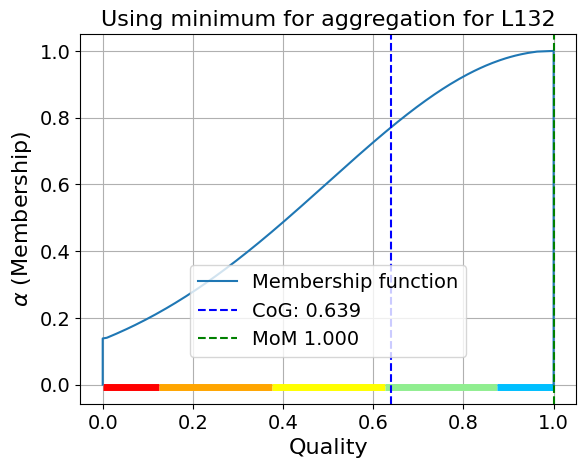

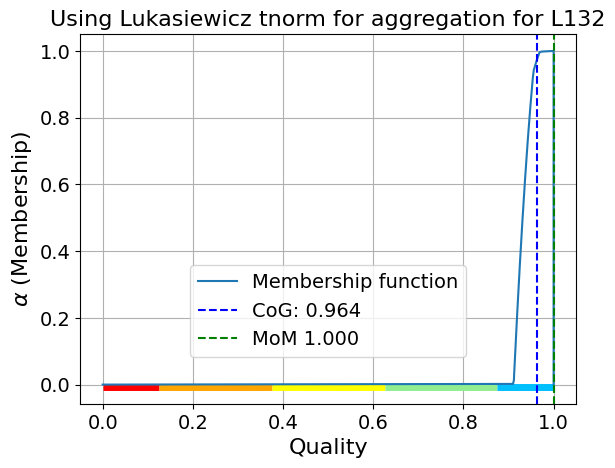

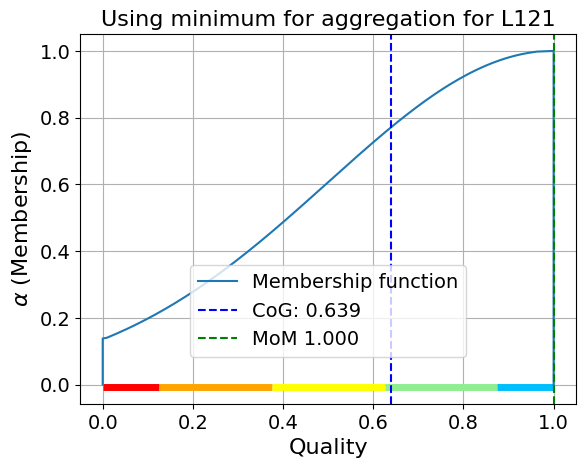

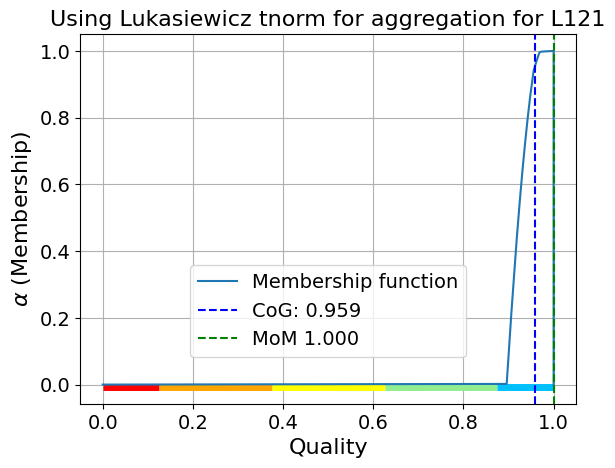

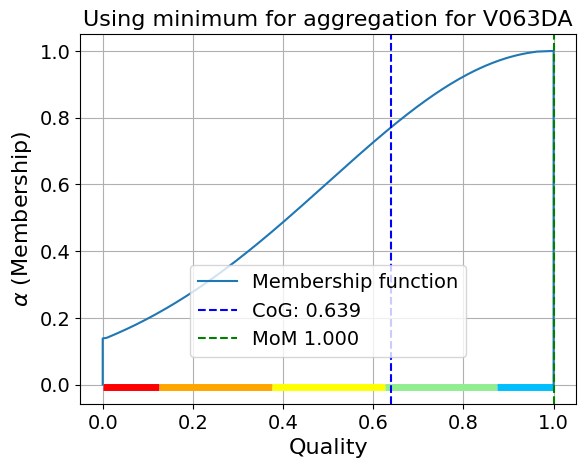

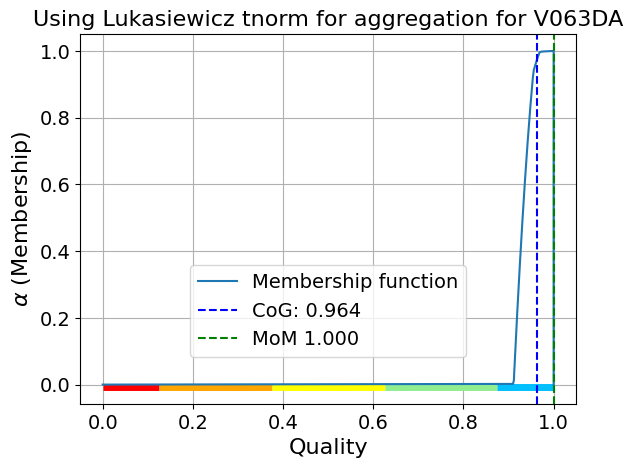

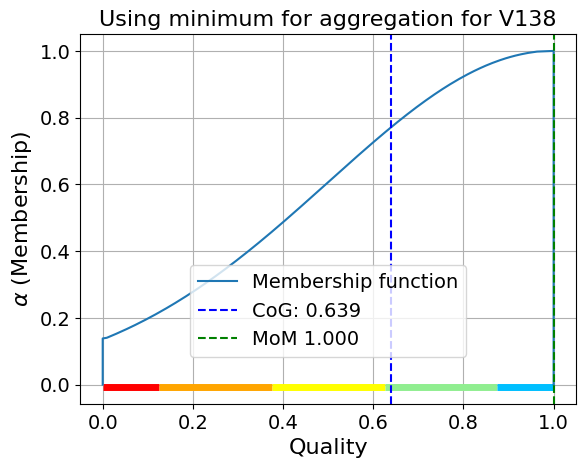

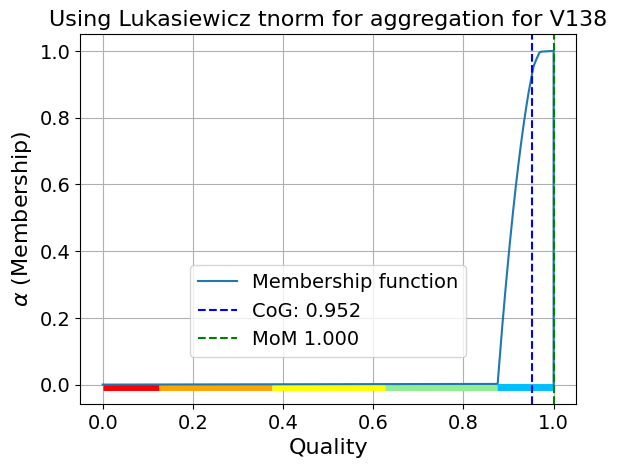

In [67]:
 
# Iterates trough the samples and performs inference and evaluation
for row in comparison_df.itertuples():
    data_type = row[2]
    sample_name = row[1]
    sample = row[2:-1]
    currenct_quality_grid = filter_qualityGrid_from_data(water_type=data_type)
    
 
    implicative_system = ImplicativeInferenceSystem(currenct_quality_grid, type_of_modifier='altm',
                                                number_of_grid_points=Number_of_grid_points,
                                                type_of_tnorm='luk', aggregate_with_same_tnorm=False)


    membership_value  = implicative_system.inference(sample)
    membership_value.plot(label = f'Using minimum for aggregation for {sample_name}')
    
    implicative_system = ImplicativeInferenceSystem(currenct_quality_grid, type_of_modifier='altm',
                                                    number_of_grid_points=Number_of_grid_points,
                                                    type_of_tnorm='luk', aggregate_with_same_tnorm=True)
    

    membership_value  = implicative_system.inference(sample)
    membership_value.plot(label = f'Using Lukasiewicz tnorm for aggregation for {sample_name}')